# Komplexe Netzwerke

Das Notebook vergleicht die drei Grundmodelle der Netzwerkwissenschaft (Erdős–Rényi, Watts–Strogatz, Barabási–Albert) mit networkx: Gradverteilung, Riesenkomponente, Kleine-Welt-Effekt aus kurzen Wegen und hoher Clusterung. Über das Spektrum der Adjazenz- und Laplace-Matrix verbindet es Netzwerke mit Zufallsmatrizen und findet Gemeinschaften, und es untersucht zwei Formen von Dynamik auf Netzen: die Schwelle einer Epidemie (als Kantenperkolation) und die Synchronisation gekoppelter Oszillatoren im Kuramoto-Modell.

Welche Struktur haben große Netzwerke, und wie bestimmt diese Struktur, was sich auf ihnen ausbreitet oder synchronisiert?

#### **Hintergrund**

Viele Systeme bestehen aus Einheiten und ihren Verbindungen: Menschen und ihre Kontakte, Webseiten und ihre Links, Proteine und ihre Wechselwirkungen, Kraftwerke und Leitungen, Nervenzellen und Synapsen. Die **Netzwerkwissenschaft** beschreibt solche Systeme als Graphen und fragt, welche Struktur große Netze haben und wie diese Struktur bestimmt, was auf ihnen passiert: wie schnell sich eine Krankheit oder ein Gerücht ausbreitet, ob ein Netz Ausfälle verkraftet, ob gekoppelte Oszillatoren in Gleichtakt kommen.

Die Graphentheorie beginnt mit Eulers Königsberger Brückenproblem (1736). Erdős und Rényi untersuchten 1959/60 Zufallsgraphen als reine Mathematik. Milgrams Briefexperiment (1967) zeigte, dass sich fast beliebige Menschen über wenige Zwischenstationen erreichen („six degrees“). Watts und Strogatz (1998) erklärten mit einem einfachen Modell, wie kurze Wege und dichte Cliquen zusammengehen, Barabási und Albert (1999), warum reale Netze wenige Knoten mit sehr vielen Verbindungen haben. Heute sind Netzwerkmethoden Alltag in der Epidemiologie (Kontaktnetze, Impfstrategien), bei Suchmaschinen (PageRank ist ein Eigenvektor), in der Biologie, bei der Stabilität von Stromnetzen und im maschinellen Lernen: Graph Neural Networks rechnen auf Graphen, und spektrale Methoden nutzen die Eigenvektoren der Laplace-Matrix.

Landkarte:

- **Drei Modelle**
  - Erdős–Rényi, Watts–Strogatz, Barabási–Albert als kleine Graphen (Code-Teil): wie die Modelle aussehen, wenn man jeden Knoten sieht.
- **Struktur**
  - Gradverteilungen (Exp. 1): Poisson bei Erdős–Rényi, schmal bei Watts–Strogatz, Potenzgesetz $k^{-3}$ mit Hubs bei Barabási–Albert.
  - Riesenkomponente (Exp. 2): Ab $\langle k\rangle = 1$ hängt ein fester Anteil aller Knoten zusammen, $S = 1 - e^{-\langle k\rangle S}$.
  - Kleine Welt (Exp. 3): Wenige Abkürzungen machen die Wege kurz, während die Cliquen erhalten bleiben.
- **Spektren**
  - Halbkreis und Fiedler-Vektor (Exp. 4): Die Adjazenzmatrix eines Zufallsgraphen ist eine Zufallsmatrix; der zweite Eigenvektor der Laplace-Matrix findet Gemeinschaften.
- **Dynamik auf Netzen**
  - Epidemien als Perkolation (Exp. 5): Die Schwelle $T_c = \langle k\rangle/(\langle k^2\rangle - \langle k\rangle)$ ist in skalenfreien Netzen viel kleiner.
  - Synchronisation im Kuramoto-Modell (Exp. 6): Ab $K_c = 2/(\pi g(0))$ rasten Oszillatoren in einen gemeinsamen Takt ein.

Verwandte Notebooks: Halbkreis und Niveaustatistik in [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb), Bifurkationen und Lyapunov-Exponenten in [Dynamische Systeme und Chaos](https://github.com/deltorobarba/science/blob/main/maths/chaos.ipynb).

#### **Theorie**

##### *1. Graphen und ihre Kenngrößen*

Ein Netzwerk besteht aus $N$ Knoten und Kanten zwischen ihnen, beschrieben durch die **Adjazenzmatrix** $A_{ij} = 1$, wenn $i$ und $j$ verbunden sind. Der **Grad** $k_i = \sum_jA_{ij}$ ist die Zahl der Nachbarn, $P(k)$ die **Gradverteilung**, $\langle k\rangle$ und $\langle k^2\rangle$ ihre Momente. Weitere Kenngrößen:
- **Mittlere Weglänge** $L$: die mittlere Zahl der Schritte auf dem kürzesten Weg zwischen zwei Knoten.
- **Clusterkoeffizient** $C$: der Anteil der Paare von Nachbarn eines Knotens, die selbst verbunden sind („die Freunde meiner Freunde sind meine Freunde“), gemittelt über die Knoten.
- **Riesenkomponente:** ein zusammenhängender Teil, der einen festen Bruchteil aller Knoten enthält, während alle anderen Komponenten höchstens logarithmisch mit $N$ wachsen.
- **Exzessgrad:** Folgt man einer zufälligen Kante, landet man bei einem Knoten mit Grad $k$ mit Wahrscheinlichkeit $\propto kP(k)$ (Knoten mit vielen Kanten werden öfter erreicht, das **Freundschaftsparadoxon**); er hat im Mittel $(\langle k^2\rangle - \langle k\rangle)/\langle k\rangle$ weitere Kanten.

##### *2. Erdős–Rényi: Zufallsgraphen*

Jede der $N(N-1)/2$ möglichen Kanten existiert unabhängig mit Wahrscheinlichkeit $p$. Der Grad ist binomialverteilt, für großes $N$ bei festem $\langle k\rangle = p(N - 1)$ **Poisson-verteilt**, $P(k) = e^{-\langle k\rangle}\langle k\rangle^k/k!$; große Grade sind extrem selten.
- **Riesenkomponente:** Sei $u$ die Wahrscheinlichkeit, dass ein Knoten nicht zur Riesenkomponente gehört; das gilt, wenn keiner seiner Nachbarn zu ihr gehört, also $u = \sum_kP(k)u^k = e^{\langle k\rangle(u - 1)}$. Für den Anteil $S = 1 - u$ folgt $S = 1 - e^{-\langle k\rangle S}$, mit einer Lösung $S>0$ nur für $\langle k\rangle>1$. Anschaulich ist die Breitensuche von einem Knoten aus ein **Verzweigungsprozess** mit im Mittel $\langle k\rangle$ Nachkommen: Ist das mehr als einer, kann er ewig weiterwachsen. Der Übergang ist stetig, knapp oberhalb ist $S\approx2(\langle k\rangle - 1)$; genau bei $\langle k\rangle = 1$ wächst die größte Komponente wie $N^{2/3}$.
- **Wege und Clusterung:** In $\ell$ Schritten erreicht man etwa $\langle k\rangle^\ell$ Knoten, also alle nach $L\approx\ln N/\ln\langle k\rangle$ Schritten. Zwei Nachbarn eines Knotens sind mit Wahrscheinlichkeit $p$ verbunden: $C = p$, verschwindend klein.

##### *3. Watts–Strogatz: kleine Welten*

Ein Ring, in dem jeder Knoten mit seinen $k$ nächsten Nachbarn verbunden ist, hat lange Wege, $L\approx N/2k$, und eine hohe Clusterung, $C = 3(k - 2)/(4(k - 1))$ (für $k = 10$ also 0.667). Legt man jede Kante mit Wahrscheinlichkeit $p$ an einem Ende auf einen zufälligen Knoten um, entstehen **Abkürzungen**: Jede verkürzt viele Wege zugleich, zerstört aber nur wenige Dreiecke, $C(p)\approx C(0)(1 - p)^3$ (Barrat und Weigt 2000). Schon für $p\approx0.01$ sind die Wege kurz und die Clusterung hoch: eine **kleine Welt**, wie in sozialen Netzen.

##### *4. Barabási–Albert: skalenfreie Netze*

Das Netz wächst; jeder neue Knoten verbindet sich mit $m$ bestehenden, bevorzugt mit solchen, die schon viele Kanten haben (**bevorzugtes Anhängen**, „die Reichen werden reicher“). Zur Zeit $t$ ist die Summe aller Grade $2mt$, der Knoten $i$ wird mit Wahrscheinlichkeit $k_i/2mt$ gewählt, und es folgt $dk_i/dt = k_i/2t$, also $k_i(t) = m(t/t_i)^{1/2}$ mit der Ankunftszeit $t_i$. Weil die Ankunftszeiten gleichmäßig verteilt sind, ist der Anteil der Knoten mit Grad mindestens $k$ gleich $(m/k)^2$, und die Gradverteilung ist ein **Potenzgesetz** $P(k)\approx2m^2/k^3$, genauer $2m(m+1)/(k(k+1)(k+2))$. Solche Netze heißen **skalenfrei**: Es gibt keinen typischen Grad, aber wenige **Hubs** mit sehr vielen Kanten; der größte Grad wächst wie $m\sqrt N$. In der doppelt logarithmischen Darstellung ist ein Potenzgesetz eine Gerade; ob reale Daten wirklich einem folgen, prüft man mit statistischen Tests (Clauset, Shalizi und Newman 2009).

##### *5. Spektren: Adjazenz- und Laplace-Matrix*

- **Adjazenzspektrum:** Beim Erdős–Rényi-Graphen ist $A$ eine symmetrische Zufallsmatrix mit Einträgen 0 und 1. Zieht man den Mittelwert ab, bleibt eine Matrix mit Varianz $p(1 - p)$ pro Eintrag; ihre Eigenwerte füllen einen **Halbkreis** vom Radius $2\sqrt{Np(1 - p)}$, wie bei den Gaußschen Ensembles. Der abgezogene Mittelwert, eine Matrix vom Rang 1, erzeugt einen einzelnen großen Eigenwert bei etwa $Np + 1$.
- **Laplace-Matrix:** $\mathcal L = D - A$ ($D$ diagonal mit den Graden) erfüllt $x^T\mathcal Lx = \sum_{\text{Kanten }(i,j)}(x_i - x_j)^2\geq0$. Ihre Eigenwerte sind also nicht negativ, und der Eigenwert 0 kommt so oft vor, wie der Graph Zusammenhangskomponenten hat.
- **Fiedler-Vektor und spektrales Clustering:** Teilt man die Knoten in zwei Gruppen mit $x_i = \pm1$, zählt $x^T\mathcal Lx/4$ die Kanten zwischen den Gruppen. Erlaubt man beliebige reelle Werte senkrecht zum konstanten Vektor, ist das Minimum der Eigenvektor zum zweitkleinsten Eigenwert, der **Fiedler-Vektor**. Seine Vorzeichen teilen das Netz in zwei etwa gleich große Teile mit wenigen Kanten dazwischen. Ein Testfall ist das **stochastische Blockmodell**: Gruppen, innerhalb derer Kanten wahrscheinlicher sind als zwischen ihnen.

##### *6. Epidemien als Perkolation*

Jede Kante zu einem Infizierten überträgt die Krankheit mit Wahrscheinlichkeit $T$ (**Transmissibilität**). Ein über eine Kante erreichter Knoten hat im Mittel $(\langle k^2\rangle - \langle k\rangle)/\langle k\rangle$ weitere Kanten, also steckt jeder Infizierte im Mittel $R = T(\langle k^2\rangle - \langle k\rangle)/\langle k\rangle$ weitere an, und eine große Epidemie ist möglich, wenn $R>1$:
$$T_c = \frac{\langle k\rangle}{\langle k^2\rangle - \langle k\rangle} .$$
Beim Erdős–Rényi-Graphen ist $\langle k^2\rangle - \langle k\rangle = \langle k\rangle^2$, also $T_c = 1/\langle k\rangle$. Bei skalenfreien Netzen mit $P(k)\propto k^{-3}$ wächst $\langle k^2\rangle$ mit der Größe des Netzes ohne Grenze (bei Barabási–Albert wie $m(m+1)\ln N$), und die Schwelle geht gegen null (Pastor-Satorras und Vespignani 2001). Die Endgröße der Epidemie ist die Riesenkomponente des Graphen, in dem jede Kante nur mit Wahrscheinlichkeit $T$ behalten wird (**Kantenperkolation**, Newman 2002); exakt gilt das, wenn alle Infizierten gleich lange ansteckend sind.

##### *7. Synchronisation: das Kuramoto-Modell*

$N$ Oszillatoren mit Eigenfrequenzen $\omega_i$ (Dichte $g(\omega)$, symmetrisch um 0) koppeln alle miteinander:
$$\dot\theta_i = \omega_i + \frac KN\sum_j\sin(\theta_j - \theta_i) = \omega_i + Kr\sin(\psi - \theta_i),\qquad re^{i\psi} = \frac1N\sum_je^{i\theta_j} .$$
Der **Ordnungsparameter** $r$ misst die Synchronisation ($r = 0$: Phasen gleichmäßig verteilt, $r = 1$: alle im Gleichtakt). Jeder Oszillator spürt nur das mittlere Feld. Oszillatoren mit $\vert\omega_i\vert\leq Kr$ rasten bei $\sin(\theta_i - \psi) = \omega_i/(Kr)$ ein, die übrigen laufen weiter. Verlangt man, dass die eingerasteten zusammen wieder genau $r$ ergeben, folgt $1 = K\int_{-\pi/2}^{\pi/2}\cos^2\phi\,g(Kr\sin\phi)\,d\phi$, und für $r\to0$ die **kritische Kopplung**
$$K_c = \frac2{\pi g(0)},$$
für eine Normalverteilung mit Breite 1 also $K_c = 2\sqrt{2\pi}/\pi\approx1.60$. Unterhalb läuft jeder Oszillator mit seiner eigenen Frequenz, oberhalb wächst ein synchronisierter Kern (eine Bifurkation). Beispiele sind Herzschrittmacherzellen, Glühwürmchen und Generatoren im Stromnetz.

#### **Code**

Die drei Modelle mit gleichem mittlerem Grad und Hilfsfunktionen.

In [1]:
# Alles hier (numpy, networkx, matplotlib) ist in Colab vorinstalliert
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from scipy.stats import poisson as poisson_dist

rng = np.random.default_rng(2)
SEED = 2
N, K_MEAN = 3000, 6

def models(N, k_mean, seed=SEED):
    return {"Erdős–Rényi": nx.fast_gnp_random_graph(N, k_mean / (N - 1), seed=seed),
            "Watts–Strogatz (p = 0.1)": nx.watts_strogatz_graph(N, k_mean, 0.1, seed=seed),
            "Barabási–Albert (m = 3)": nx.barabasi_albert_graph(N, k_mean // 2, seed=seed)}

def giant_fraction(G):
    return max((len(c) for c in nx.connected_components(G)), default=0) / G.number_of_nodes()

graphs = models(N, K_MEAN)
for name, G in graphs.items():
    deg = np.array([d for _, d in G.degree()])
    print(f"{name:26s}: {G.number_of_edges()} Kanten, ⟨k⟩ = {deg.mean():.2f}, ⟨k²⟩ = {np.mean(deg ** 2):.1f}, größter Grad {deg.max()}")

Erdős–Rényi               : 9059 Kanten, ⟨k⟩ = 6.04, ⟨k²⟩ = 42.3, größter Grad 17
Watts–Strogatz (p = 0.1)  : 9000 Kanten, ⟨k⟩ = 6.00, ⟨k²⟩ = 36.6, größter Grad 10
Barabási–Albert (m = 3)   : 8991 Kanten, ⟨k⟩ = 5.99, ⟨k²⟩ = 97.2, größter Grad 155


Wie sehen die drei Modelle aus, wenn das Netz so klein ist, dass man jeden Knoten einzeln sieht? Gezeichnet werden je $N = 30$ Knoten mit Sollwert $\langle k\rangle = 6$; die Knotengröße wächst mit dem Grad. Watts–Strogatz steht im Ringlayout, damit die Abkürzungen als Sehnen sichtbar werden, die beiden anderen im Kräftelayout.

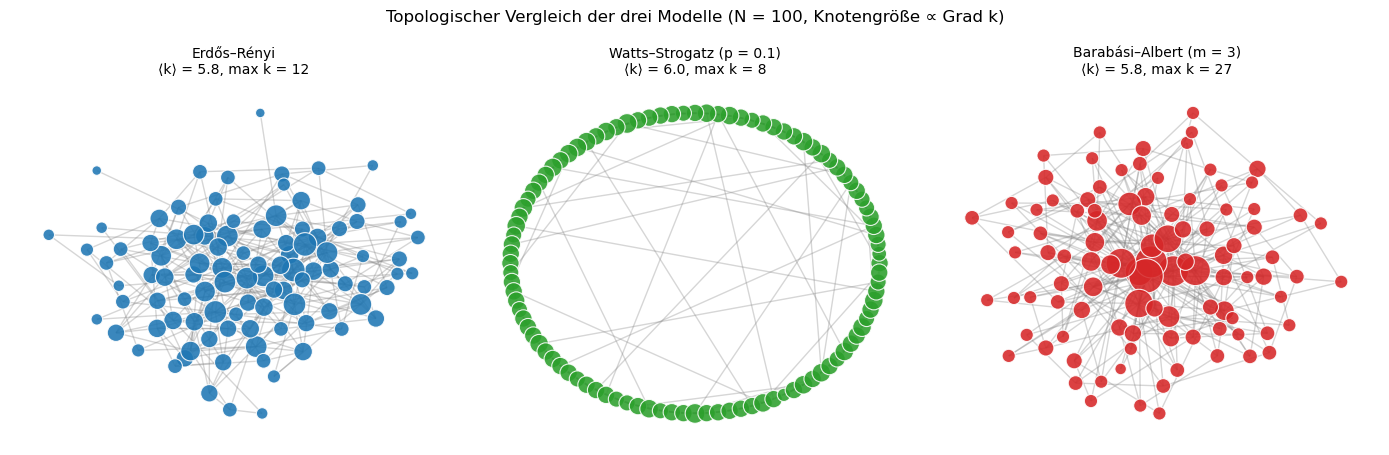

In [2]:
# Visualisierung kleinerer Graphen (N = 30, ⟨k⟩ = 6), um die Topologie direkt zu erkennen
N_vis = 100
small_graphs = models(N_vis, K_MEAN)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
colors = ["tab:blue", "tab:green", "tab:red"]
layouts = ["spring", "circular", "spring"]

for ax, (name, G), c, layout in zip(axes, small_graphs.items(), colors, layouts):
    deg = np.array([d for _, d in G.degree()])
    pos = nx.circular_layout(G) if layout == "circular" else nx.spring_layout(G, k=0.55, seed=SEED)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.32, edge_color="gray", width=1.0)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=25 + 22 * deg, node_color=c,
                           alpha=0.88, edgecolors="white", linewidths=0.8)
    ax.set_title(f"{name}\n⟨k⟩ = {deg.mean():.1f}, max k = {deg.max()}", fontsize=10)
    ax.axis("off")

fig.suptitle(f"Topologischer Vergleich der drei Modelle (N = {N_vis}, Knotengröße ∝ Grad k)", fontsize=12)
fig.tight_layout()
plt.show()

* **Erdős–Rényi (links, Kräftelayout):** Ein homogenes Zufallsnetz ohne geometrische Ordnung oder Hierarchie. Fast alle Knoten haben ähnlich viele Nachbarn (ähnliche Knotengröße; ⟨k⟩ = 4.9, größter Grad 10; der Sollwert 6 wird bei nur 30 Knoten zufällig verfehlt). Dreiecke entstehen nur zufällig (hier 19), und kein Knoten dominiert.
* **Watts–Strogatz (Mitte, Ringlayout):** Die meisten Kanten verlaufen entlang des Rings zu den unmittelbaren Nachbarn und bilden lokale Dreiecke (hohe Clusterung). Einzelne zufällig umgelegte Kanten (*Shortcuts*) spannen sich als lange Sehnen quer durch das Innere des Kreises und verkürzen die globalen Wege drastisch.
* **Barabási–Albert (rechts, Kräftelayout):** Durch das bevorzugte Anhängen (*Preferential Attachment*) sammeln die ältesten Knoten die meisten Kanten: Die größten **Hubs** liegen im Zentrum (hier bis Grad 14 bei 30 Knoten), während viele spät hinzugekommene Knoten am Rand nur die m = 3 Kanten haben, mit denen sie angekommen sind (einzelne Knoten des kleinen Startgraphen sogar weniger).
* **Warum Erdős–Rényi und Barabási–Albert hier ähnlich aussehen:** Bei 30 Knoten ist der Unterschied noch klein; über 50 Ziehungen ist der größte Grad im Mittel 10.9 (Erdős–Rényi) gegen 15.5 (Barabási–Albert). Das Potenzgesetz wirkt erst in großen Netzen: Der größte Grad wächst bei Barabási–Albert wie $m\sqrt N$ (Theorie, Abschnitt 4, mit $t_i \approx 1$), bei Erdős–Rényi nur sehr langsam, etwa wie $\ln N/\ln\ln N$. Mit $N = 200$ und $m = 2$ sind es im Mittel schon 37 gegen 10.

#### **Experimente**

##### *1. Gradverteilungen*

Wie unterscheiden sich die Gradverteilungen der drei Modelle bei gleichem mittlerem Grad, und folgt Barabási–Albert dem Potenzgesetz $k^{-3}$?

Gezeigt ist der Anteil der Knoten mit Grad mindestens $k$ (komplementäre Verteilungsfunktion). Sie ist weniger verrauscht als ein Histogramm; für $P(k) \propto k^{-3}$ fällt sie wie $k^{-2}$ (Abschnitt 4 der Theorie).

**Hintergrund & Fachbegriffe:**
- **Grad ($k$) und Gradverteilung ($P(k)$):** Der Grad eines Knotens ist die Anzahl seiner direkten Kanten (Nachbarn). Die Gradverteilung $P(k)$ gibt die Wahrscheinlichkeit an, dass ein zufällig gewählter Knoten genau den Grad $k$ besitzt.
- **Homogene vs. skalenfreie Netze (Potenzgesetz & Hubs):** Im Erdős–Rényi- und Watts–Strogatz-Modell streuen die Grade eng um den Erwartungswert $\langle k \rangle$; die Verteilung fällt für große $k$ überexponentiell schnell ab, sodass eine charakteristische Größenskala existiert. Beim **bevorzugten Anhängen (Preferential Attachment)** im Barabási–Albert-Modell wächst die Bindungswahrscheinlichkeit neuer Kanten linear mit dem bereits vorhandenen Grad. Dadurch entsteht eine **skalenfreie Verteilung** (Potenzgesetz $P(k) \propto k^{-\gamma}$ mit $\gamma = 3$), die keine typische Skala besitzt und einzelne hochvernetzte Knoten (**Hubs**) hervorbringt.
- **Komplementäre Verteilungsfunktion (CCDF):** Sie ist definiert als der kumulative Schwanzanteil $F_c(k) = P(\text{Grad} \ge k) = \sum_{k' \ge k} P(k')$. Während ein direktes Histogramm von $P(k)$ bei großen Graden durch diskrete Einzelereignisse (0 oder 1 Knoten pro Grad) stark verrauscht ist, glättet die Summation dieses Rauschen. Wegen $\int_k^\infty k'^{-\gamma}\,dk' \propto k^{-(\gamma - 1)}$ zeigt sich ein Potenzgesetz $P(k) \propto k^{-3}$ in der doppelt-logarithmischen Darstellung von $F_c(k)$ als Gerade mit der Steigung $-(\gamma - 1) = -2$.

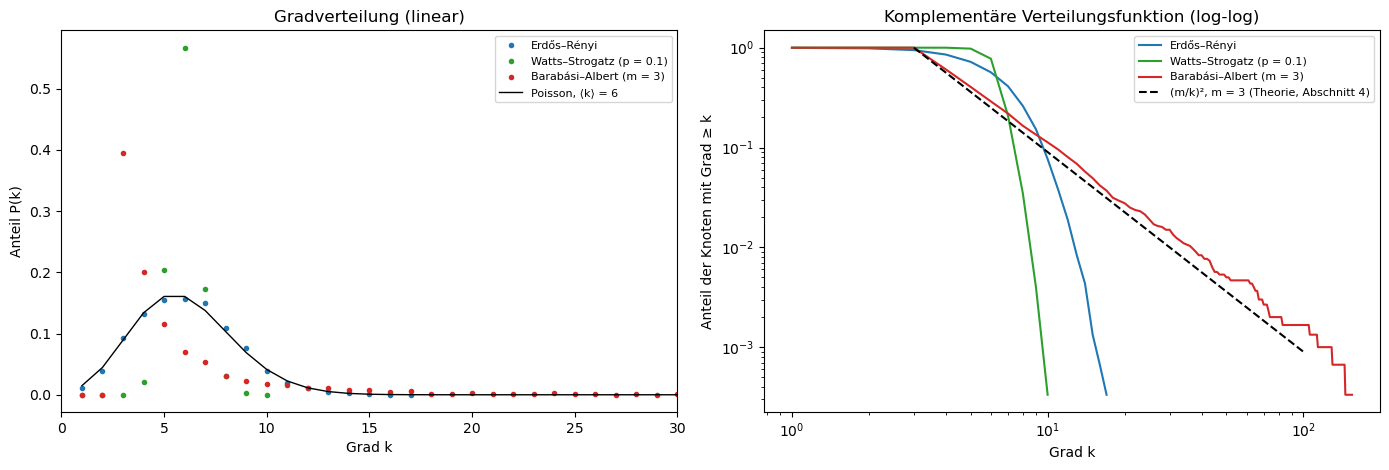

Barabási–Albert: Steigung der komplementären Verteilung zwischen k = 6 und 60: -1.87  (Theorie −2, also P(k) ∝ k^-2.87)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for (name, G), c in zip(graphs.items(), ["tab:blue", "tab:green", "tab:red"]):
    deg = np.array([d for _, d in G.degree()])
    ks = np.arange(1, deg.max() + 1)
    axes[0].plot(ks, [np.mean(deg == k) for k in ks], "o", ms=3, c=c, label=name)
    ccdf = [np.mean(deg >= k) for k in ks]
    axes[1].loglog(ks, ccdf, "-", c=c, label=name)
kk = np.arange(1, 40)
axes[0].plot(kk, poisson_dist.pmf(kk, K_MEAN), c="black", lw=1, label=f"Poisson, ⟨k⟩ = {K_MEAN}")
axes[0].set_xlim(0, 30)
axes[0].set_xlabel("Grad k")
axes[0].set_ylabel("Anteil P(k)")
axes[0].set_title("Gradverteilung (linear)")
axes[0].legend(fontsize=8)
k_ref = np.logspace(np.log10(3), 2, 50)
axes[1].loglog(k_ref, (3 / k_ref) ** 2, c="black", ls="--", label="(m/k)², m = 3 (Theorie, Abschnitt 4)")
axes[1].set_xlabel("Grad k")
axes[1].set_ylabel("Anteil der Knoten mit Grad ≥ k")
axes[1].set_title("Komplementäre Verteilungsfunktion (log-log)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

deg_ba = np.array([d for _, d in graphs["Barabási–Albert (m = 3)"].degree()])
ks = np.arange(6, 60)
slope = np.polyfit(np.log(ks), np.log([np.mean(deg_ba >= k) for k in ks]), 1)[0]
print(f"Barabási–Albert: Steigung der komplementären Verteilung zwischen k = 6 und 60: {slope:.2f}  "
      f"(Theorie −2, also P(k) ∝ k^{slope - 1:.2f})")

* Im **linken Teilplot (lineare Skala)** ist die klassische Gradverteilung $P(k)$ für die drei Netzwerkmodelle aus `models` (je $N = 3000$ Knoten, mittlerer Grad $\langle k \rangle \approx 6$) dargestellt. Man sieht, dass der Erdős–Rényi-Graph (blaue Punkte) eng der theoretischen Poisson-Verteilung (schwarze Linie) um $\langle k \rangle = 6$ folgt und der Watts–Strogatz-Graph (grüne Punkte) noch schmaler um den Wert 6 konzentriert ist, weil fast alle Knoten noch nahe am ursprünglichen Ring-Grad liegen (größter Grad $10$ bei Watts–Strogatz, $17$ bei Erdős–Rényi). Das Barabási–Albert-Modell (rote Punkte) beginnt hingegen erst bei $k = m = 3$ mit einem hohen Wert und fällt dann flach ab, wobei einzelne Knoten („Hubs“) im linearen Bereich gar nicht mehr sichtbar sind, weil ihr Grad bis auf $155$ reicht.
* Der **rechte Teilplot (doppelt-logarithmische Skala)** zeigt deshalb die komplementäre Verteilungsfunktion $P(\text{Grad} \ge k)$, also den Anteil der Knoten mit mindestens $k$ Kanten, was das starke statistische Rauschen im oberen Schwanz glättet. Während die grüne (Watts–Strogatz) und blaue Kurve (Erdős–Rényi) ab $k \approx 10$ steil nach unten abknicken (exponentieller Abfall, keine Hubs), verläuft die rote Barabási–Albert-Kurve auf der Log-Log-Skala als Gerade parallel zur theoretischen Referenzlinie $(m/k)^2$ (schwarz gestrichelt). Eine Gerade im Log-Log-Plot passt zu einem Potenzgesetz (skalenfreies Netz), ist aber noch kein Beweis; dafür braucht man einen statistischen Test gegen andere Verteilungen (Clauset, Shalizi und Newman 2009). Da das Integral über $P(k) \propto k^{-\gamma}$ eine komplementäre Verteilung $\propto k^{-(\gamma - 1)}$ ergibt, entspricht die im Bereich $k \in [6, 60]$ gemessene Steigung von $-1.87$ (theoretisch $-2$) einer Gradverteilung von $P(k) \propto k^{-2.87}$ (theoretisch $k^{-3}$). Die Abweichung von $-2$ hat zwei Gründe. Erstens ist die exakte Verteilung des Modells $P(k) = 2m(m+1)/(k(k+1)(k+2))$, ihre komplementäre Verteilung also $m(m+1)/(k(k+1))$; deren Steigung ist bei kleinem $k$ flacher als $-2$ ($-1.86$ bei $k = 6$), und ein Fit über $k = 6$ bis $60$ ergibt selbst für ein unendlich großes Netz $-1.95$. Zweitens streut der Schwanz bei $N = 3000$ stark, weil nur etwa zehn Knoten einen Grad über 60 haben; mit $N = 30\,000$ ergibt derselbe Fit $-1.97$.

##### *2. Die Riesenkomponente*

Ab welchem mittleren Grad entsteht im ER-Graphen eine Riesenkomponente, und wie groß ist sie?

Für jeden mittleren Grad werden fünf Graphen mit $N = 10\,000$ gezogen. Die Theorie ist die Lösung von $S = 1 - e^{-\langle k\rangle S}$ (Abschnitt 2 der Theorie).

**Hintergrund & Fachbegriffe:**
- **Zusammenhangskomponente & Riesenkomponente (Giant Component):** Eine Zusammenhangskomponente ist eine maximale Teilmenge von Knoten, in der jedes Knotenpaar über mindestens einen Pfad verbunden ist. Von einer **Riesenkomponente** spricht man im thermodynamischen Limes $N \to \infty$, wenn die größte Komponente einen echt positiven Bruchteil $S = \lim_{N\to\infty} |C_{\max}|/N > 0$ aller Knoten umfasst (also extensiv mit $\mathcal{O}(N)$ skaliert), während alle übrigen Komponenten höchstens logarithmisch ($\mathcal{O}(\ln N)$) wachsen.
- **Perkolationsübergang & Verzweigungsprozess:** Untersucht wird der topologische Phasenübergang des Erdős–Rényi-Graphen $G(N, p)$ bei Variation des mittleren Grades $\langle k \rangle = p(N-1)$. Lokal lässt sich die Breitensuche von einem Startknoten aus durch einen **Galton–Watson-Verzweigungsprozess** mit Poisson-verteilter Nachkommenzahl (Erwartungswert $\langle k \rangle$) approximieren: Für $\langle k \rangle < 1$ (unterkritisch) stirbt jede lokale Erkundung mit Wahrscheinlichkeit $1$ im Endlichen aus ($S = 0$). Oberhalb des kritischen Punkts, für $\langle k \rangle > 1$ (überkritisch), existiert eine positive Überlebenswahrscheinlichkeit $S > 0$ (genau bei $\langle k \rangle_c = 1$ stirbt der Prozess noch mit Wahrscheinlichkeit 1 aus), die als nichttriviale Lösung der Selbstkonsistenzgleichung $S = 1 - e^{-\langle k \rangle S}$ bestimmt wird.

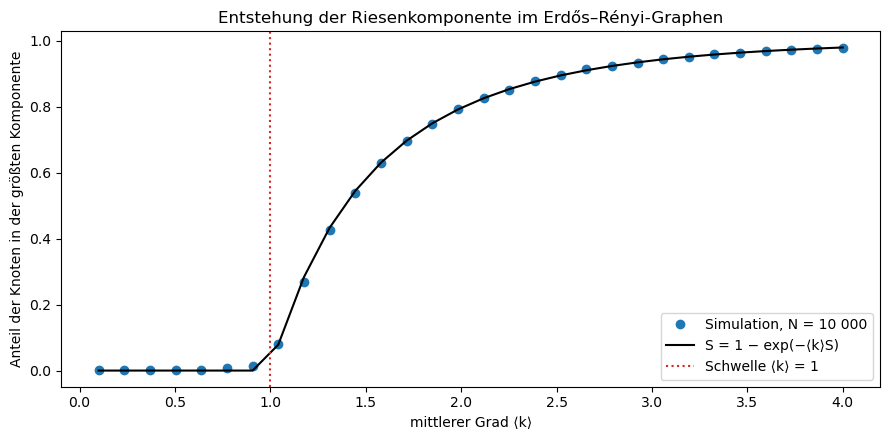

⟨k⟩ = 0.5: Simulation 0.002, Theorie 0.000
⟨k⟩ = 1.0: Simulation 0.040, Theorie 0.000
⟨k⟩ = 1.5: Simulation 0.575, Theorie 0.583
⟨k⟩ = 2.0: Simulation 0.799, Theorie 0.797
⟨k⟩ = 3.0: Simulation 0.941, Theorie 0.940


In [4]:
def giant_theory(k):
    S = 1.0
    for _ in range(500):
        S = 1 - np.exp(-k * S)
    return S if k > 1 else 0.0

k_grid = np.linspace(0.1, 4, 30)
S_sim = [np.mean([giant_fraction(nx.fast_gnp_random_graph(10_000, k / 9999, seed=s)) for s in range(5)]) for k in k_grid]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(k_grid, S_sim, "o", label="Simulation, N = 10 000")
ax.plot(k_grid, [giant_theory(k) for k in k_grid], c="black", label="S = 1 − exp(−⟨k⟩S)")
ax.axvline(1, color="tab:red", ls=":", label="Schwelle ⟨k⟩ = 1")
ax.set_xlabel("mittlerer Grad ⟨k⟩")
ax.set_ylabel("Anteil der Knoten in der größten Komponente")
ax.set_title("Entstehung der Riesenkomponente im Erdős–Rényi-Graphen")
ax.legend()
fig.tight_layout()
plt.show()
for k in [0.5, 1.0, 1.5, 2.0, 3.0]:
    print(f"⟨k⟩ = {k}: Simulation {np.mean([giant_fraction(nx.fast_gnp_random_graph(10_000, k / 9999, seed=s)) for s in range(5)]):.3f}, Theorie {giant_theory(k):.3f}")

* Der Plot zeigt auf der x-Achse den mittleren Grad $\langle k \rangle$ eines Erdős–Rényi-Zufallsgraphen ($N = 10\,000$) und auf der y-Achse den relativen Anteil $S$ der Knoten, die zur größten zusammenhängenden Komponente gehören (berechnet über `giant_fraction`).
* Man erkennt einen scharfen Phasenübergang an der rot gepunkteten vertikalen Schwelle $\langle k \rangle = 1$: Links davon ($\langle k \rangle < 1$) liegen die blauen Simulationspunkte flach bei fast null, weil das Netzwerk nur aus vielen kleinen, isolierten Bäumen besteht. 
* Sobald jeder Knoten im Schnitt mehr als einen Nachbarn hat ($\langle k \rangle > 1$), wachsen die Teilbäume zu einer einzigen „Riesenkomponente“ zusammen, die einen endlichen Bruchteil des gesamten Netzwerks umfasst. Der Übergang ist stetig, kein Sprung: Knapp oberhalb der Schwelle ist $S \approx 2(\langle k \rangle - 1)$, die Kurve steigt also aus null heraus linear an.
* Die Zahlenwerte belegen, wie präzise die Selbstkonsistenzgleichung $S = 1 - e^{-\langle k \rangle S}$ (schwarze Kurve) das Verhalten im Grenzfall großer Netze beschreibt: Schon bei $\langle k \rangle = 1.5$ sind rund $58\,\%$ aller Knoten miteinander verbunden, bei $\langle k \rangle = 2.0$ bereits $80\,\%$ und bei $\langle k \rangle = 3.0$ rund $94\,\%$. Direkt am kritischen Punkt $\langle k \rangle = 1.0$ sagt die unendliche Theorie noch $0.000$ voraus, während die Simulation $0.040$ ($4\,\%$) liefert – das ist ein bekannter Finite-Size-Effekt, da die größte Komponente am kritischen Punkt wie $N^{2/3}$ skaliert (bei $N = 10\,000$ sind $N^{2/3}/N = N^{-1/3} \approx 4.6\,\%$).

##### *3. Die kleine Welt*

Wie ändern sich mittlere Weglänge und Clusterung, wenn man im Ring immer mehr Kanten zufällig umlegt?

Watts–Strogatz mit $N = 1000$ und $k = 10$; beide Größen relativ zum Ring ($p = 0$), wie in der Originalarbeit.

**Hintergrund & Fachbegriffe:**
- **Mittlere Weglänge ($L$):** Das arithmetische Mittel der geodätischen Distanz $d(i, j)$ (Anzahl der Kanten auf dem kürzesten Pfad zwischen Knoten $i$ und $j$) über alle $\binom{N}{2}$ Knotenpaare. Sie quantifiziert die globale Transport- und Kommunikationseffizienz des Netzwerks.
- **Clusterkoeffizient ($C$):** Ein Maß für die lokale Transitivität (Dreiecksbildung). Für einen Knoten $i$ mit Grad $k_i$ gibt der lokale Clusterkoeffizient an, welcher Bruchteil der $\binom{k_i}{2}$ möglichen Kanten zwischen seinen unmittelbaren Nachbarn tatsächlich existiert (wie oft also zwei Nachbarn eines Knotens auch untereinander verbunden sind); $C$ ist der Mittelwert über alle Knoten.
- **Small-World-Effekt (Kleine-Welt-Eigenschaft):** Untersucht wird der strukturelle Übergang zwischen einem regulären Ringgitter ($p = 0$: hohe lokale Ordnung $C(0) = 3(k-2)/(4(k-1))$, für $k = 10$ also $0.667$, für großes $k$ gegen $3/4$, aber lange geodätische Wege $L(0) \sim N/(2k)$) und einem völlig zufälligen Graphen ($p = 1$: kurze logarithmische Wege $L(1) \sim \ln N / \ln k$, aber verschwindende Clusterung $C(1) \sim k/N$). Durch zufälliges Umlegen (*Rewiring*) eines Endes jeder Kante mit Wahrscheinlichkeit $p$ entstehen weitreichende **Shortcuts** (Fernverbindungen): Bereits ein winziger Anteil $p \ll 1$ solcher Abkürzungen senkt $L(p)$ global drastisch ab, während die lokale Nachbarschaftsstruktur nahezu unversehrt bleibt, $C(p) \approx C(0)(1-p)^3$ (Barrat und Weigt 2000).

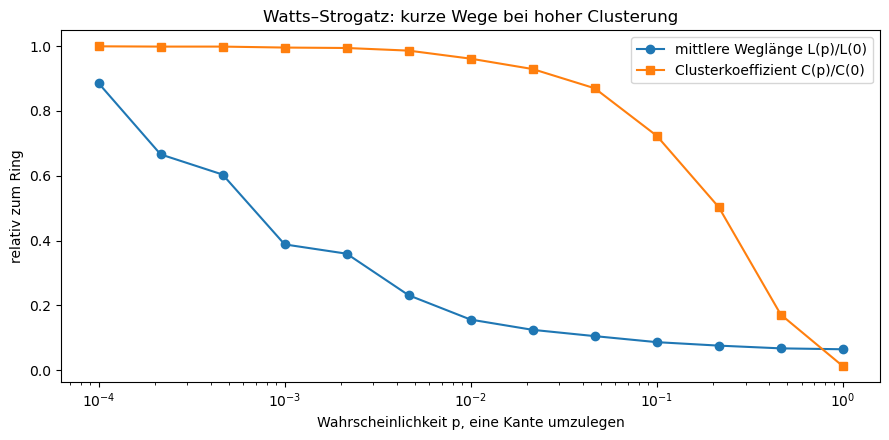

Ring: L(0) = 50.5 (N/2k = 50), C(0) = 0.667 (3(k−2)/4(k−1) = 0.667)
bei p = 0.010: L/L(0) = 0.16, C/C(0) = 0.96


In [5]:
ps = np.logspace(-4, 0, 13)
L0 = nx.average_shortest_path_length(nx.watts_strogatz_graph(1000, 10, 0.0, seed=SEED))
C0 = nx.average_clustering(nx.watts_strogatz_graph(1000, 10, 0.0, seed=SEED))
Ls, Cs = [], []
for p in ps:
    G = nx.connected_watts_strogatz_graph(1000, 10, p, seed=SEED)
    Ls.append(nx.average_shortest_path_length(G) / L0)
    Cs.append(nx.average_clustering(G) / C0)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogx(ps, Ls, "o-", label="mittlere Weglänge L(p)/L(0)")
ax.semilogx(ps, Cs, "s-", label="Clusterkoeffizient C(p)/C(0)")
ax.set_xlabel("Wahrscheinlichkeit p, eine Kante umzulegen")
ax.set_ylabel("relativ zum Ring")
ax.set_title("Watts–Strogatz: kurze Wege bei hoher Clusterung")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Ring: L(0) = {L0:.1f} (N/2k = {1000 / 20:.0f}), C(0) = {C0:.3f} (3(k−2)/4(k−1) = {3 * 8 / 36:.3f})")
i = np.argmin(np.abs(ps - 0.01))
print(f"bei p = {ps[i]:.3f}: L/L(0) = {Ls[i]:.2f}, C/C(0) = {Cs[i]:.2f}")

* Dieser Plot reproduziert das berühmte Diagramm von Watts und Strogatz (1998) mit einer logarithmischen x-Achse für die Umlege-Wahrscheinlichkeit $p$ (von $10^{-4}$ bis $1$) und normierten Werten auf der y-Achse relativ zum regelmäßigen Ringgitter ($p = 0$). Beim reinen Ring ($N = 1000, k = 10$) sind sowohl die mittlere kürzeste Weglänge $L(0) = 50.5$ als auch der Clusterkoeffizient $C(0) = 0.667$ maximal (normiert auf $1.0$). 
* Wenn man nun $p$ erhöht, stürzt die blaue Kurve der mittleren Weglänge $L(p)/L(0)$ schon bei winzigen Werten von $p$ steil ab, während die orangefarbene Kurve des Clusterkoeffizienten $C(p)/C(0)$ bis etwa $p = 0.02$ nahezu unverändert auf einem hohen Plateau nahe $1.0$ bleibt.
* Die Ausgabe verdeutlicht diesen „Small-World“-Bereich quantitativ bei $p = 0.01$: Wenn lediglich $1\,\%$ aller Kanten zufällig umgelegt werden, bleiben $96\,\%$ der lokalen Dreiecksstrukturen (Clusterung $C/C(0) = 0.96$) erhalten, weil fast jede Nachbarschaft intakt bleibt. Gleichzeitig reichen diese wenigen zufälligen Fernverbindungen („Shortcuts“) quer durch den Ring aus, um die mittlere Weglänge im gesamten Netzwerk auf nur noch $16\,\%$ des ursprünglichen Wertes ($L/L(0) = 0.16$, also rund 8 statt 50 Schritte) schrumpfen zu lassen.

##### *4. Spektren: der Halbkreis im Zufallsgraphen und Gemeinschaften aus dem Fiedler-Vektor*

Folgen die Eigenwerte der Adjazenzmatrix eines ER-Graphen dem Halbkreis der Zufallsmatrizen, und findet der Fiedler-Vektor zwei versteckte Gemeinschaften?

Für die Gemeinschaften dient ein Blockmodell: zwei Gruppen von je 200 Knoten, Kanten innerhalb einer Gruppe mit Wahrscheinlichkeit 0.05, zwischen den Gruppen mit 0.01. Der Fiedler-Vektor kennt die Gruppen nicht; geprüft wird, wie viele Knoten seine Vorzeichen richtig zuordnen.

**Hintergrund & Fachbegriffe:**
- **Adjazenzspektrum & Wignersches Halbkreisgesetz:** Die **Adjazenzmatrix** $A \in \{0, 1\}^{N \times N}$ eines ungerichteten Graphen ist reell-symmetrisch und besitzt $N$ reelle Eigenwerte. Im Erdős–Rényi-Graphen sind die Einträge $A_{ij}$ ($i < j$) unabhängige Bernoulli-Zufallsvariablen mit Erwartungswert $p$ und Varianz $\sigma^2 = p(1-p)$. Zerlegt man $A = \tilde{A} + p\,(\mathbf{1}\mathbf{1}^T - I)$ (die Diagonale von $A$ ist null) in den zentrierten Zufallsanteil $\tilde{A}$ (Erwartungswert $0$) und die Rang-1-Mittelwertmatrix, so konvergiert die Eigenwertdichte von $\tilde{A}$ nach dem **Wignerschen Halbkreisgesetz** der Zufallsmatrixtheorie gegen einen Halbkreis mit Radius $2\sqrt{N}\sigma = 2\sqrt{Np(1-p)}$, während die Rang-1-Störung einen einzelnen dominanten Ausreißer-Eigenwert (Perron–Frobenius-Eigenwert) bei $\lambda_{\max} \approx Np + 1$ erzeugt (genauer $(N-1)p + 1 - p$; der Halbkreis drückt den Ausreißer um etwa 1 nach außen, Füredi und Komlós 1981).
- **Stochastisches Blockmodell (SBM), Graph-Laplace-Matrix & Fiedler-Vektor:** Das **Blockmodell** erzeugt Graphen mit eingebauter **Gemeinschaftsstruktur (Communities)**, indem Knoten innerhalb derselben Gruppe mit höherer Wahrscheinlichkeit ($p_{\text{in}}$) verbunden werden als zwischen verschiedenen Gruppen ($p_{\text{out}}$). Zur unüberwachten Rekonstruktion dieser Gruppen nutzt das **spektrale Clustering** die positiv semidefinite **Laplace-Matrix** $\mathcal{L} = D - A$ (mit Gradmatrix $D = \text{diag}(k_1, \dots, k_N)$). Wegen $x^T \mathcal{L} x = \sum_{\{i,j\}\in E} (x_i - x_j)^2$ gehört der kleinste Eigenwert $\lambda_1 = 0$ zum konstanten Eigenvektor $\mathbf{1}$. Nach dem Satz von Courant–Fischer minimiert der Eigenvektor zum zweitkleinsten Eigenwert $\lambda_2 > 0$ (**Fiedler-Vektor**) die quadratische Form orthogonal zu $\mathbf{1}$: Er ist die stetige Relaxierung des Problems, das Netz in zwei etwa gleich große Teile mit möglichst wenigen Kanten dazwischen zu teilen (Bisektion bzw. *Ratio Cut*; ohne die Bedingung $x \perp \mathbf{1}$ wäre der kleinste Schnitt trivial, etwa ein einzelner abgetrennter Knoten). Das Vorzeichen seiner Einträge teilt das Netz deshalb entlang eines dünnen Kantenschnitts in die beiden Gemeinschaften.

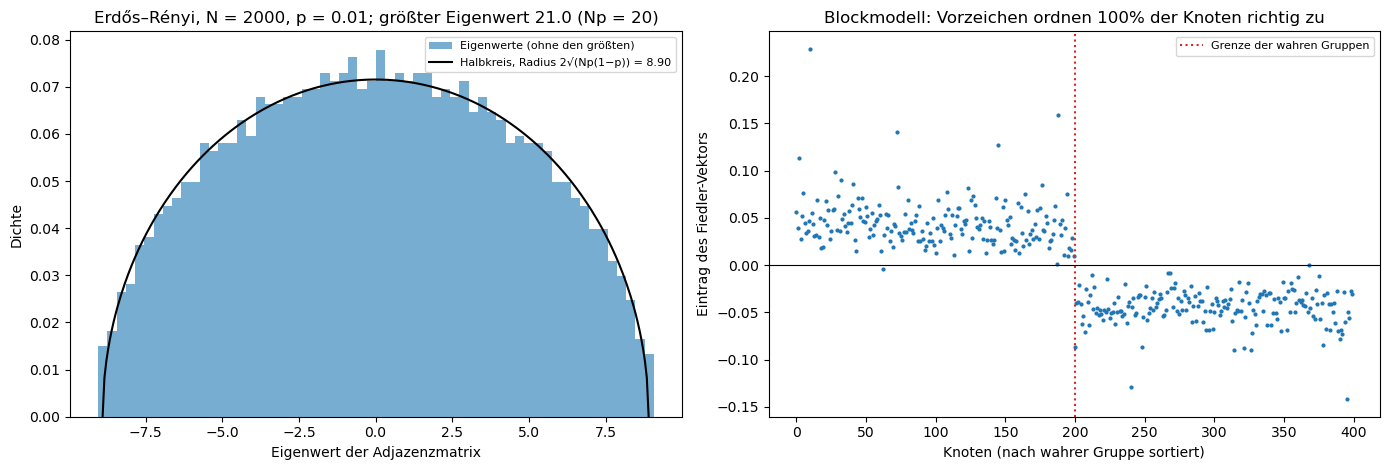

Adjazenz-Spektrum: Rand des Halbkreises 8.90, beobachtet 9.07 bis -9.05; größter Eigenwert 20.99 ≈ Np + 1 = 21
Laplace-Spektrum des Blockmodells: kleinste Eigenwerte [-0.     2.927  3.463  3.517]; Fiedler-Vektor ordnet 99.8% richtig zu


In [6]:
N_sp, p_sp = 2000, 0.01
A = nx.to_numpy_array(nx.fast_gnp_random_graph(N_sp, p_sp, seed=SEED))
ev = np.linalg.eigvalsh(A)
radius = 2 * np.sqrt(N_sp * p_sp * (1 - p_sp))

sizes, P = [200, 200], [[0.05, 0.01], [0.01, 0.05]]
G_sbm = nx.stochastic_block_model(sizes, P, seed=SEED)
truth = np.array([G_sbm.nodes[i]["block"] for i in G_sbm.nodes])
Lap = nx.laplacian_matrix(G_sbm).toarray().astype(float)
w, V = np.linalg.eigh(Lap)
fiedler = V[:, 1]
guess = (fiedler > 0).astype(int)
accuracy = max(np.mean(guess == truth), np.mean(guess != truth))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].hist(ev[:-1], bins=60, density=True, alpha=0.6, label="Eigenwerte (ohne den größten)")
xs = np.linspace(-radius, radius, 300)
axes[0].plot(xs, 2 * np.sqrt(radius ** 2 - xs ** 2) / (np.pi * radius ** 2), c="black", label=f"Halbkreis, Radius 2√(Np(1−p)) = {radius:.2f}")
axes[0].set_xlabel("Eigenwert der Adjazenzmatrix")
axes[0].set_ylabel("Dichte")
axes[0].set_title(f"Erdős–Rényi, N = {N_sp}, p = {p_sp}; größter Eigenwert {ev[-1]:.1f} (Np = {N_sp * p_sp:.0f})")
axes[0].legend(fontsize=8)
order = np.argsort(truth, kind="stable")
axes[1].plot(fiedler[order], ".", ms=4)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].axvline(200, color="tab:red", ls=":", label="Grenze der wahren Gruppen")
axes[1].set_xlabel("Knoten (nach wahrer Gruppe sortiert)")
axes[1].set_ylabel("Eintrag des Fiedler-Vektors")
axes[1].set_title(f"Blockmodell: Vorzeichen ordnen {accuracy:.0%} der Knoten richtig zu")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"Adjazenz-Spektrum: Rand des Halbkreises {radius:.2f}, beobachtet {ev[-2]:.2f} bis {ev[0]:.2f}; größter Eigenwert {ev[-1]:.2f} ≈ Np + 1 = {N_sp * p_sp + 1:.0f}")
print(f"Laplace-Spektrum des Blockmodells: kleinste Eigenwerte {np.round(w[:4], 3)}; Fiedler-Vektor ordnet {accuracy:.1%} richtig zu")

* Im **linken Teilplot** sieht man das Histogramm der Eigenwerte der Adjazenzmatrix $A$ eines Erdős–Rényi-Graphen ($N = 2000, p = 0.01$, ohne den größten Eigenwert). Die blauen Balken schmiegen sich eng an das Wignersche Halbkreisgesetz für symmetrische Zufallsmatrizen (schwarze Kurve) mit dem theoretischen Radius $2\sqrt{Np(1-p)} = 8.90$ an (beobachtete Ränder: $-9.05$ bis $9.07$). Da die Einträge von $A$ nicht den Mittelwert $0$, sondern $p$ haben, wirkt dieser Mittelwert wie eine Rang-1-Störung und schiebt einen einzigen isolierten „Ausreißer-Eigenwert“ weit nach rechts auf $20.99 \approx \langle k \rangle + 1 = 21$ (im Plottitel angegeben).
* Der **rechte Teilplot** illustriert die spektrale Gemeinschaftserkennung (Spectral Clustering) an einem stochastischen Blockmodell aus zwei Gruppen (Knoten $0$ bis $199$ und $200$ bis $399$, getrennt durch die rot gepunktete Linie), die intern dichter ($p_{\text{in}} = 0.05$) als untereinander ($p_{\text{out}} = 0.01$) verknüpft sind. Aufgetragen sind die Einträge des sogenannten Fiedler-Vektors (des Eigenvektors zum zweitkleinsten Eigenwert $\lambda_2 = 2.927$ der Laplace-Matrix $\mathcal{L} = D - A$). Obwohl der Algorithmus die Gruppenzugehörigkeit nicht kennt, liegen die Punkte links der roten Linie fast ausnahmslos im positiven Bereich ($> 0$) und rechts davon im negativen Bereich ($< 0$; welche Gruppe welches Vorzeichen bekommt, ist Zufall, denn ein Eigenvektor ist nur bis auf das Vorzeichen bestimmt), sodass allein das Vorzeichen des Fiedler-Vektors $99.8\,\%$ (im Plottitel auf $100\,\%$ gerundet) aller Knoten der richtigen Gemeinschaft zuordnet.

##### *5. Epidemien: Erdős–Rényi gegen skalenfrei*

Wie groß wird eine Epidemie in Abhängigkeit von der Transmissibilität $T$, und warum ist die Schwelle im skalenfreien Netz viel niedriger?

Beide Netze haben $N = 20\,000$ Knoten und denselben mittleren Grad 4. Die Endgröße der Epidemie ist die Riesenkomponente des Graphen, in dem jede Kante mit Wahrscheinlichkeit $T$ behalten wird (Abschnitt 6 der Theorie); gemittelt über fünf Ziehungen.

**Hintergrund & Fachbegriffe:**
- **Transmissibilität ($T$) und Kantenperkolation (Bond Percolation):** In epidemiologischen Netzwerkmodellen (wie dem Endzustand einer SIR-Dynamik, *Susceptible–Infected–Recovered*) beschreibt die **Transmissibilität** $T \in [0, 1]$ die Wahrscheinlichkeit, dass eine infizierte Person die Infektion über eine bestehende Kontaktkante weitergibt. Mathematisch lässt sich der gesamte Ausbruchsprozess auf **Kantenperkolation** abbilden: Man behält jede Kante des ursprünglichen Kontaktgraphen unabhängig mit Wahrscheinlichkeit $T$ bei (und löscht sie mit $1-T$). Sind alle Infizierten gleich lange ansteckend, entsprechen die Zusammenhangskomponenten des resultierenden Teilgraphen genau den Clustern gemeinsam Infizierter (bei unterschiedlich langen Ansteckungszeiten sind die Übertragungen über die Kanten eines Knotens nicht mehr unabhängig, und die Abbildung ist eine Näherung; Kenah und Robins 2007); eine große Epidemie tritt genau dann auf, wenn dieser perkolierte Graph eine Riesenkomponente besitzt.
- **Exzessgrad, Freundschaftsparadoxon & Epidemieschwelle ($T_c$):** Untersucht wird, ab welcher kritischen Übertragungswahrscheinlichkeit $T_c$ (der **Epidemieschwelle**) die Basisreproduktionszahl $R > 1$ wird. Erreicht die Infektion über eine zufällige Kante einen neuen Knoten, ist dessen Grad $k$ nicht gemäß $P(k)$ verteilt, sondern proportional zu $k P(k)$ (**Freundschaftsparadoxon**: Knoten mit vielen Kanten werden proportional häufiger getroffen). Die mittlere Anzahl *weiterer* ausgehender Kanten dieses Knotens (**mittlerer Exzessgrad**) beträgt daher $\langle k(k-1) \rangle / \langle k \rangle = (\langle k^2 \rangle - \langle k \rangle)/\langle k \rangle$. Weil in skalenfreien Netzen das zweite Moment $\langle k^2 \rangle$ durch die Hubs dominiert wird (und für $P(k) \propto k^{-3}$ im Limes $N \to \infty$ divergiert), schrumpft die Schwelle $T_c = \langle k \rangle / (\langle k^2 \rangle - \langle k \rangle)$ im Vergleich zum homogenen Erdős–Rényi-Graphen drastisch zusammen.

Erdős–Rényi     : T_c (Theorie) = 0.248;  Endgröße bei T = 0.2: 0.004


Barabási–Albert : T_c (Theorie) = 0.065;  Endgröße bei T = 0.2: 0.185


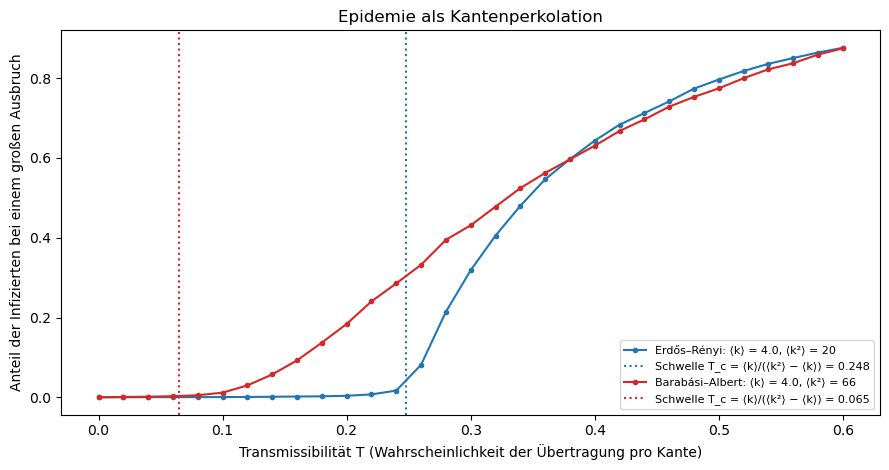

In [7]:
def percolated_giant(G, T, rng):
    keep = [e for e in G.edges() if rng.random() < T]
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    H.add_edges_from(keep)
    return giant_fraction(H)

nets = {"Erdős–Rényi": nx.fast_gnp_random_graph(20_000, 4 / 19_999, seed=SEED),
        "Barabási–Albert": nx.barabasi_albert_graph(20_000, 2, seed=SEED)}
Ts = np.linspace(0.0, 0.6, 31)
fig, ax = plt.subplots(figsize=(9, 4.8))
for (name, G), c in zip(nets.items(), ["tab:blue", "tab:red"]):
    deg = np.array([d for _, d in G.degree()])
    Tc = deg.mean() / (np.mean(deg ** 2) - deg.mean())
    sizes_ = [np.mean([percolated_giant(G, T, rng) for _ in range(5)]) for T in Ts]
    ax.plot(Ts, sizes_, "o-", ms=3, c=c, label=f"{name}: ⟨k⟩ = {deg.mean():.1f}, ⟨k²⟩ = {np.mean(deg ** 2):.0f}")
    ax.axvline(Tc, color=c, ls=":", label=f"Schwelle T_c = ⟨k⟩/(⟨k²⟩ − ⟨k⟩) = {Tc:.3f}")
    print(f"{name:16s}: T_c (Theorie) = {Tc:.3f};  Endgröße bei T = 0.2: {np.mean([percolated_giant(G, 0.2, rng) for _ in range(5)]):.3f}")
ax.set_xlabel("Transmissibilität T (Wahrscheinlichkeit der Übertragung pro Kante)")
ax.set_ylabel("Anteil der Infizierten bei einem großen Ausbruch")
ax.set_title("Epidemie als Kantenperkolation")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

* Der Plot vergleicht die Endgröße einer Epidemie (Anteil der Infizierten auf der y-Achse, modelliert durch Kantenperkolation in `percolated_giant`) in Abhängigkeit von der Übertragungswahrscheinlichkeit pro Kontakt $T$ (Transmissibilität, x-Achse) für ein Erdős–Rényi-Netz (blau) und ein skalenfreies Barabási–Albert-Netz (rot), die beide $N = 20\,000$ Knoten und praktisch denselben mittleren Grad $\langle k \rangle = 4.0$ besitzen. Während die blaue Kurve bis zur blau gepunkteten Schwelle $T_c = 0.248 \approx 1/\langle k \rangle$ komplett flach bei null verläuft und erst danach steil ansteigt, liegt die Schwelle des skalenfreien Netzes viel tiefer (rot gepunktete Linie, $T_c = 0.065$). Oberhalb davon ist die rote Kurve zwar nicht mehr null, aber zunächst winzig; sichtbar steigt sie ab etwa $T \approx 0.1$ an, immer noch deutlich vor der blauen. In skalenfreien Netzen wächst die Riesenkomponente oberhalb der Schwelle nur sehr langsam.
* Der Grund für diesen dramatischen Unterschied liegt im zweiten Moment $\langle k^2 \rangle$ der Gradverteilung, das in die Epidemieschwelle $T_c = \langle k \rangle / (\langle k^2 \rangle - \langle k \rangle)$ eingeht: Im Erdős–Rényi-Netz ist $\langle k^2 \rangle = 20$ klein, im Barabási–Albert-Netz treiben die hochvernetzten Hubs („Superspreader“) den Wert auf $\langle k^2 \rangle = 66$ (in einem unendlich großen skalenfreien Netz divergiert $\langle k^2 \rangle$, bei Barabási–Albert langsam wie $m(m+1)\ln N$, und $T_c \to 0$). Das zahlenmäßige Ergebnis bei $T = 0.2$ zeigt die Konsequenz für den Infektionsschutz: Eine Krankheit mit $20\,\%$ Übertragungswahrscheinlichkeit bleibt im Erdős–Rényi-Netz klein (die größte Komponente umfasst $0.4\,\%$), verursacht aber im skalenfreien Netz trotz identischer durchschnittlicher Kontaktzahl bereits eine große Epidemie, die $18.5\,\%$ der Population erfasst.

##### *6. Synchronisation: das Kuramoto-Modell*

Ab welcher Kopplungsstärke synchronisieren sich 2000 Oszillatoren mit zufälligen Eigenfrequenzen, und stimmt die Schwelle mit $K_c = 2/(\pi g(0))$ überein?

Die Eigenfrequenzen sind normalverteilt mit Breite 1, also $K_c \approx 1.60$. Für jede Kopplung wird 200 Zeiteinheiten integriert und $r$ über die zweite Hälfte gemittelt.

**Hintergrund & Fachbegriffe:**
- **Kuramoto-Modell & Phasen-Oszillatoren:** Das Kuramoto-Modell ist das fundamentale Paradigma für spontane Synchronisation in Populationen gekoppelter nichtlinearer Oszillatoren. Jeder Oszillator $i \in \{1, \dots, N\}$ wird durch seine Phase $\theta_i(t) \in S^1$ auf dem Einheitskreis und eine fest gezogene intrinsische **Eigenfrequenz** $\omega_i \sim g(\omega)$ beschrieben. Die Bewegungsgleichung $\dot{\theta}_i = \omega_i + \frac{K}{N}\sum_{j=1}^N \sin(\theta_j - \theta_i)$ beschreibt das Kräftemessen zwischen der heterogenen Frequenzstreuung $g(\omega)$ (die die Phasen desynchronisiert) und einer globalen, sinusförmigen Kopplung der Stärke $K \ge 0$ (die Phasenunterschiede ausgleicht).
- **Ordnungsparameter ($r$), Molekularfeld (Mean-Field) & Bifurkation bei $K_c$:** Der komplexe **Ordnungsparameter** $z = r e^{i\psi} = \frac{1}{N}\sum_{j=1}^N e^{i\theta_j}$ gibt den Schwerpunkt der Phasenpunkte auf dem Einheitskreis in der komplexen Ebene an; sein Betrag $r \in [0, 1]$ misst die makroskopische Kohärenz ($r = 0$: völlige Inkohärenz/Gleichverteilung, $r = 1$: perfekter Gleichschritt). Mit $z$ lässt sich die Dynamik exakt als **Molekularfeld-Gleichung (Mean-Field)** $\dot{\theta}_i = \omega_i + K r \sin(\psi - \theta_i)$ schreiben, in der jeder Oszillator nur an das gemeinsame mittlere Feld koppelt. Untersucht wird der Phasenübergang (superkritische **Bifurkation**) an der kritischen Kopplung $K_c = 2/(\pi g(0))$: Für $K < K_c$ zerfällt jede Kohärenz ($r = 0$), während für $K > K_c$ alle Oszillatoren mit moderater Eigenfrequenz $|\omega_i| \le K r$ in eine feste Phasenbeziehung zum mittleren Feld einrasten (**Phase-Locking**) und gemeinsam ein makroskopisches Feld $r > 0$ aufrechterhalten.

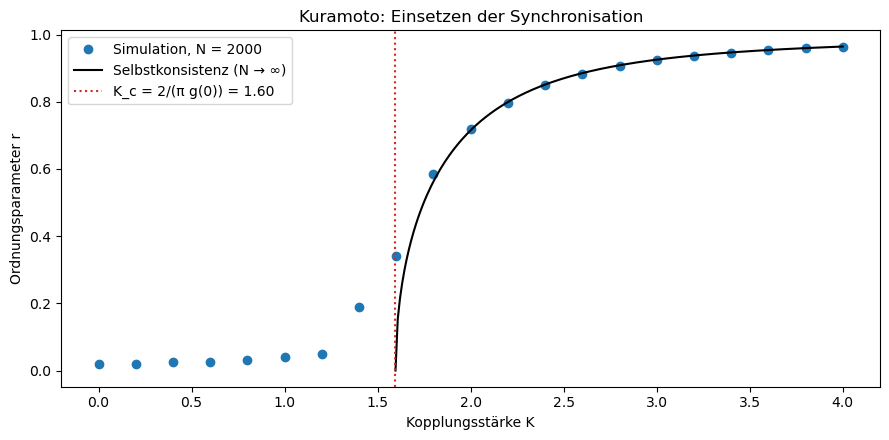

K = 1.0: Simulation r = 0.041, Theorie 0.000
K = 2.0: Simulation r = 0.719, Theorie 0.715
K = 3.0: Simulation r = 0.923, Theorie 0.925


In [8]:
N_osc = 2000
omega = rng.normal(0, 1, N_osc)
Kc = 2 / (np.pi * (1 / np.sqrt(2 * np.pi)))

def kuramoto_r(K, T=200.0, dt=0.05):
    theta = rng.uniform(0, 2 * np.pi, N_osc)
    rs = []
    for step in range(int(T / dt)):
        z = np.mean(np.exp(1j * theta))                        # r e^{iψ}
        theta += dt * (omega + K * np.abs(z) * np.sin(np.angle(z) - theta))
        if step * dt > T / 2:
            rs.append(np.abs(z))
    return np.mean(rs)

Ks = np.linspace(0, 4, 21)
r_K = [kuramoto_r(K) for K in Ks]
K_fine = np.linspace(Kc, 4, 200)

def r_theory(K):
    """Selbstkonsistenz r = K r ∫ cos²φ g(K r sin φ) dφ für die Normalverteilung, gelöst durch Bisektion."""
    phi = np.linspace(-np.pi / 2, np.pi / 2, 2001)
    g = lambda w: np.exp(-w ** 2 / 2) / np.sqrt(2 * np.pi)
    f = lambda r: K * trapezoid(np.cos(phi) ** 2 * g(K * r * np.sin(phi)), phi) - 1
    lo, hi = 1e-9, 1.0
    if f(lo) < 0:
        return 0.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if f(mid) > 0 else (lo, mid)
    return lo

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(Ks, r_K, "o", label=f"Simulation, N = {N_osc}")
ax.plot(K_fine, [r_theory(K) for K in K_fine], c="black", label="Selbstkonsistenz (N → ∞)")
ax.axvline(Kc, color="tab:red", ls=":", label=f"K_c = 2/(π g(0)) = {Kc:.2f}")
ax.set_xlabel("Kopplungsstärke K")
ax.set_ylabel("Ordnungsparameter r")
ax.set_title("Kuramoto: Einsetzen der Synchronisation")
ax.legend()
fig.tight_layout()
plt.show()
for K in [1.0, 2.0, 3.0]:
    print(f"K = {K}: Simulation r = {r_K[np.argmin(np.abs(Ks - K))]:.3f}, Theorie {r_theory(K):.3f}")

* In diesem Plot wird der Übergang zur kollektiven Synchronisation von $N = 2000$ gekoppelten Oszillatoren untersucht (berechnet über `kuramoto_r`): Auf der x-Achse ist die Kopplungsstärke $K$ aufgetragen, auf der y-Achse der Ordnungsparameter $r \in [0, 1]$, der angibt, wie stark die Oszillatoren im Gleichtakt schwingen ($r = 0$ bedeutet völlig inkohärente Phasen, $r = 1$ perfekter Gleichschritt). Unterhalb der rot gepunkteten kritischen Kopplungsstärke $K_c = 2/(\pi g(0)) \approx 1.60$ reichen die Kopplungskräfte nicht aus, um die zufälligen, normalverteilten Eigenfrequenzen zu überwinden – die blauen Simulationspunkte bleiben nahe null.
* Ab dem Schwellenwert $K_c \approx 1.60$ setzt eine Bifurkation ein: Es bildet sich ein wachsender synchronisierter Kern von Oszillatoren, und die blauen Punkte der Simulation folgen eng der schwarzen Theoriekurve der Selbstkonsistenzgleichung für $N \to \infty$. Die Textausgabe bestätigt diese Übereinstimmung quantitativ: Bei schwacher Kopplung ($K = 1.0$) herrscht noch Unordnung ($r = 0.041$ statt $0.000$ wegen endlicher Schwankungen der Größenordnung $1/\sqrt{N} \approx 0.02$, die unterhalb von $K_c$ durch die Kopplung verstärkt werden), während oberhalb der Schwelle bei $K = 2.0$ ($r = 0.719$ vs. Theorie $0.715$) und $K = 3.0$ ($r = 0.923$ vs. Theorie $0.925$) bereits der Großteil der Oszillatoren synchron im selben Takt schwingt.

#### **Ergebnis**

Beim Lauf vom 2026-10-12:

- **Gradverteilungen:** Bei gleichem mittlerem Grad 6 ist der größte Grad 17 (Erdős–Rényi), 10 (Watts–Strogatz) und 155 (Barabási–Albert). Erdős–Rényi folgt der Poisson-Verteilung; bei Barabási–Albert fällt der Anteil der Knoten mit Grad mindestens $k$ mit der Steigung $-1.87$ (Theorie $-2$; die exakte Verteilung $2m(m+1)/(k(k+1)(k+2))$ gibt in diesem Bereich $-1.95$, der Rest ist Streuung im dünn besetzten Schwanz).
- **Riesenkomponente:** Unter $\langle k\rangle = 1$ gibt es keine. Genau bei $\langle k\rangle = 1$ enthält die größte Komponente 4 % der Knoten; am kritischen Punkt wächst sie nur wie $N^{2/3}$, das sind bei $N = 10\,000$ etwa 4.6 %. Darüber stimmt die Simulation mit $S = 1 - e^{-\langle k\rangle S}$ überein (0.575/0.799/0.941 gegen 0.583/0.797/0.940 bei $\langle k\rangle$ = 1.5/2/3).
- **Kleine Welt:** Der Ring hat $L = 50.5$ und $C = 0.667$, wie berechnet. Wenn nur 1 % der Kanten umgelegt werden, schrumpft die mittlere Weglänge auf 16 %, die Clusterung bleibt bei 96 %.
- **Spektren:** Die Eigenwerte der Adjazenzmatrix füllen den Halbkreis vom Radius 8.9 wie bei einer Zufallsmatrix; ein einzelner Eigenwert liegt bei 21.0, nahe $Np + 1 = 21$. Im Blockmodell ordnet das Vorzeichen des Fiedler-Vektors 99.8 % der Knoten der richtigen Gruppe zu, ohne die Gruppen zu kennen.
- **Epidemien:** Die Schwelle ist $T_c = 0.248$ im Erdős–Rényi-Graphen ($1/\langle k\rangle = 0.25$) und $0.065$ im skalenfreien Netz mit gleichem mittlerem Grad. Bei $T = 0.2$ gibt es im ersten keinen großen Ausbruch, im zweiten erkranken 18.5 %. Die Hubs machen den Unterschied: Sie werden früh erreicht und stecken viele an.
- **Synchronisation:** Unterhalb von $K_c = 1.60$ bleibt $r$ klein (etwa 0.04, Schwankungen bei endlichem $N$); darüber wächst es wie berechnet, $r = 0.719$ bei $K = 2$ (Theorie 0.715) und $0.923$ bei $K = 3$ (0.925).

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Gezielter Angriff:** Entferne im Barabási–Albert-Netz nacheinander die Knoten mit dem höchsten Grad, und zum Vergleich zufällige Knoten. Wie schnell zerfällt die Riesenkomponente? *(Vorhersage: zufällige Ausfälle verkraftet es gut, den Verlust weniger Hubs nicht.)*
2. **Impfen der Hubs:** Impfe in Experiment 5 die 5 % Knoten mit dem höchsten Grad (entferne sie vor der Perkolation). Wie stark verschiebt sich die Schwelle im skalenfreien Netz, und wie im ER-Graphen?
3. **Kuramoto auf einem Netz:** Ersetze die Kopplung aller mit allen durch die Kopplung nur über die Kanten eines Watts–Strogatz-Graphen. Wie hängt die Synchronisation von $p$ ab?
4. **Schwächere Gemeinschaften:** Verringere im Blockmodell die Dichte innerhalb der Gruppen schrittweise. Ab wann findet der Fiedler-Vektor die Gruppen nicht mehr?

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Wie ist der Grad im Erdős–Rényi-Graphen verteilt, und warum gibt es dort keine Hubs?</summary>

Poisson-verteilt mit Mittelwert $\langle k\rangle$; die Wahrscheinlichkeit großer Grade fällt schneller als exponentiell, deshalb sind Knoten mit sehr vielen Kanten praktisch ausgeschlossen.
</details>

<details><summary>2. Ab welchem mittleren Grad entsteht eine Riesenkomponente, und welche Gleichung bestimmt ihre Größe?</summary>

Ab $\langle k\rangle = 1$, wenn die Breitensuche im Mittel mehr als einen neuen Knoten pro Schritt findet. $S = 1 - e^{-\langle k\rangle S}$; knapp oberhalb wächst $S$ stetig wie $2(\langle k\rangle - 1)$.
</details>

<details><summary>3. Was ist eine kleine Welt, und wie entsteht sie im Watts–Strogatz-Modell?</summary>

Kurze mittlere Wege bei hoher Clusterung. Wenige zufällig umgelegte Kanten im Ring sind Abkürzungen, die viele Wege zugleich verkürzen, aber kaum Dreiecke zerstören.
</details>

<details><summary>4. Warum führt bevorzugtes Anhängen zu einem Potenzgesetz?</summary>

Ein Knoten gewinnt Kanten proportional zu seinem Grad, $dk_i/dt = k_i/2t$, also $k_i = m\sqrt{t/t_i}$: Frühe Knoten wachsen am meisten. Mit gleichverteilten Ankunftszeiten folgt $P(k)\propto k^{-3}$.
</details>

<details><summary>5. Was zeigt eine Gerade im doppelt logarithmischen Plot der komplementären Verteilung, und was nicht?</summary>

Sie passt zu einem Potenzgesetz; ihre Steigung ist $-(\gamma - 1)$. Ein Beweis ist sie nicht, dafür braucht man einen statistischen Test gegen andere Verteilungen.
</details>

<details><summary>6. Welches Spektrum hat die Adjazenzmatrix eines Erdős–Rényi-Graphen?</summary>

Einen Halbkreis vom Radius $2\sqrt{Np(1 - p)}$ und einen einzelnen Ausreißer bei etwa $Np + 1$, der vom Mittelwert der Einträge kommt.
</details>

<details><summary>7. Wie findet der Fiedler-Vektor zwei Gemeinschaften?</summary>

Er minimiert $\sum_{\text{Kanten}}(x_i - x_j)^2$ senkrecht zum konstanten Vektor, die stetige Version eines Schnitts in zwei gleich große Teile mit wenigen Kanten dazwischen; seine Vorzeichen geben die beiden Gruppen.
</details>

<details><summary>8. Wie hängt die Epidemieschwelle von der Gradverteilung ab?</summary>

$T_c = \langle k\rangle/(\langle k^2\rangle - \langle k\rangle)$. Hubs machen $\langle k^2\rangle$ groß und die Schwelle klein; in skalenfreien Netzen geht sie für großes $N$ gegen null.
</details>

<details><summary>9. Warum ist die Endgröße einer Epidemie die Riesenkomponente eines perkolierten Graphen?</summary>

Wenn jede Kante unabhängig mit Wahrscheinlichkeit $T$ überträgt, erreicht die Infektion vom ersten Fall aus genau die Knoten, die über behaltene Kanten mit ihm verbunden sind.
</details>

<details><summary>10. Was misst der Ordnungsparameter im Kuramoto-Modell, und wo liegt die kritische Kopplung?</summary>

$r = \vert\frac1N\sum e^{i\theta_j}\vert$, 0 bei gleichverteilten Phasen und 1 im Gleichtakt. $K_c = 2/(\pi g(0))$, bei normalverteilten Eigenfrequenzen mit Breite 1 also 1.60.
</details>

#### **Nächste Schritte**

- **Reale Netze:** Netzwerkdaten (zum Beispiel aus der Sammlung SNAP der Stanford University oder `nx.karate_club_graph()`) mit denselben Größen untersuchen und mit den Modellen vergleichen.
- **Gemeinschaftserkennung im Großen:** Modularität und der Louvain-Algorithmus (`nx.community.louvain_communities`) statt nur zwei Gruppen.
- **Epidemien in der Zeit:** SIR-Simulation Schritt für Schritt statt Perkolation, mit Zeitverlauf und Impfstrategien.
- **Verbindungen:** Das Spektrum ist eine Zufallsmatrix (Notebook `randommatrices.ipynb`), und die Synchronisation ist ein dynamisches System mit Bifurkation bei $K_c$ (Notebook `chaos.ipynb`).

#### **Referenzen**

- Newman, M. E. J. (2018): *Networks*, 2nd ed., Oxford University Press; Kap. 11 (Zufallsgraphen), 12 (Konfigurationsmodell), 13 (Wachstumsmodelle), 15 (Perkolation), 16 (Epidemien).
- Barabási, A.-L. (2016): *Network Science*, Cambridge University Press (frei lesbar unter networksciencebook.com).
- Erdős, P. & Rényi, A. (1960): *On the evolution of random graphs*, Publ. Math. Inst. Hung. Acad. Sci. 5, 17.
- Watts, D. J. & Strogatz, S. H. (1998): *Collective dynamics of 'small-world' networks*, Nature 393, 440.
- Barabási, A.-L. & Albert, R. (1999): *Emergence of Scaling in Random Networks*, Science 286, 509.
- Pastor-Satorras, R. & Vespignani, A. (2001): *Epidemic Spreading in Scale-Free Networks*, Phys. Rev. Lett. 86, 3200.
- Newman, M. E. J. (2002): *Spread of epidemic disease on networks*, Phys. Rev. E 66, 016128.
- Füredi, Z. & Komlós, J. (1981): *The eigenvalues of random symmetric matrices*, Combinatorica 1, 233.
- Barrat, A. & Weigt, M. (2000): *On the properties of small-world network models*, Eur. Phys. J. B 13, 547.
- Kenah, E. & Robins, J. M. (2007): *Second look at the spread of epidemics on networks*, Phys. Rev. E 76, 036113.
- Clauset, A., Shalizi, C. R. & Newman, M. E. J. (2009): *Power-law distributions in empirical data*, SIAM Review 51, 661.
- Strogatz, S. H. (2000): *From Kuramoto to Crawford: exploring the onset of synchronization in populations of coupled oscillators*, Physica D 143, 1.